# Steel Quality Analytics
## Inspection priorities from labeled fault observations

**Tools:** pandas, SQLite, Matplotlib. **Source:** UCI Steel Plates Faults, 1,941 observations.

**Question:** Which fault categories and steel groups should a quality team investigate first?

This is descriptive analysis of a public research sample. No defect-free records or production totals exist, so the analysis cannot estimate rejection rates, downtime or savings. [Source and attribution](https://doi.org/10.24432/C5J88N).

In [1]:
from pathlib import Path
import sys
import sqlite3
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw').exists(), 'Run from the project root or notebooks folder.'
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.pipeline import load_raw, validate, transform, fault_summary, queries, main
pd.set_option('display.max_columns', 12)
raw = load_raw()
raw.head()

Out[1]: 
   X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  ...  \
0         42         50     270900     270944           267           17  ...   
1        645        651    2538079    2538108           108           10  ...   
2        829        835    1553913    1553931            71            8  ...   
3        853        860     369370     369415           176           13  ...   
4       1289       1306     498078     498335          2409           60  ...   

   Z_Scratch  K_Scatch  Stains  Dirtiness  Bumps  Other_Faults  
0          0         0       0          0      0             0  
1          0         0       0          0      0             0  
2          0         0       0          0      0             0  
3          0         0       0          0      0             0  
4          0         0       0          0      0             0  

[5 rows x 34 columns]


## 1. Validate before aggregating
Checks cover missing/non-finite values, binary one-hot labels, steel flags, positive area/thickness and coordinate order. Exact duplicates are counted, not silently removed. The audit cannot prove that every original measurement is correct.

In [2]:
audit = validate(raw)
pd.Series(audit)

Out[2]: 
rows                                                                 1941
columns                                                                34
missing_cells                                                           0
exact_duplicate_rows                                                    0
validation                                                         passed
duplicate_policy        Flag, do not drop: identical measurements may ...
dtype: object


## 2. Build a tidy table with traceable rows
Convert source labels into categories. Preserve measurements and all observations. Thickness bands use source units because a physical unit is not documented. `record_id` is a generated source-row identifier, not a unique plate ID.

In [3]:
df = transform(raw)
print(f'{len(df):,} rows, {len(df.columns)} clean fields')
display(df[['record_id','fault_type','steel_type','thickness_band','pixels_areas']].head())
assert len(df) == len(raw) and df.record_id.is_unique

1,941 rows, 30 clean fields


,record_id,fault_type,steel_type,thickness_band,pixels_areas
0,1,Pastry,A300,51-100,267
1,2,Pastry,A300,51-100,108
2,3,Pastry,A300,51-100,71
3,4,Pastry,A400,>100,176
4,5,Pastry,A400,>100,2409


## 3. Run the SQL analysis
The SQL file uses CTEs and window functions for cumulative shares, within-group denominators and rankings. Execute against an in-memory database to make this notebook independently checkable.

In [4]:
with sqlite3.connect(':memory:') as con:
    df.to_sql('faults', con, index=False)
    results = {name: pd.read_sql_query(sql, con) for name, sql in queries()}
display(results['overall_kpis'])
display(results['fault_pareto'])

,fault_records,fault_categories,steel_types,mean_pixel_area,summed_pixel_area
0,1941,7,2,1893.88,3676018


,fault_type,records,record_share_pct,cumulative_share_pct
0,Other Faults,673,34.67,34.67
1,Bumps,402,20.71,55.38
2,K Scratch,391,20.14,75.53
3,Z Scratch,190,9.79,85.32
4,Pastry,158,8.14,93.46
5,Stains,72,3.71,97.17
6,Dirtiness,55,2.83,100.00


**Interpretation:** Other Faults, Bumps and K Scratch together account for 75.53% of recorded observations. Four categories are needed to exceed 80%; do not claim an exact 80/20 relationship.

Top-three share: 75.53%
{
  "records": 1941,
  "top_three_record_share_pct": 75.52807831014941,
  "top_three_categories": [
    "Other Faults",
    "Bumps",
    "K Scratch"
  ],
  "k_scratch_pixel_share_pct": 81.07843868011528,
  "k_scratch_record_share_pct": 20.14425553838228
}
Pipeline complete. Outputs: data/processed and reports.


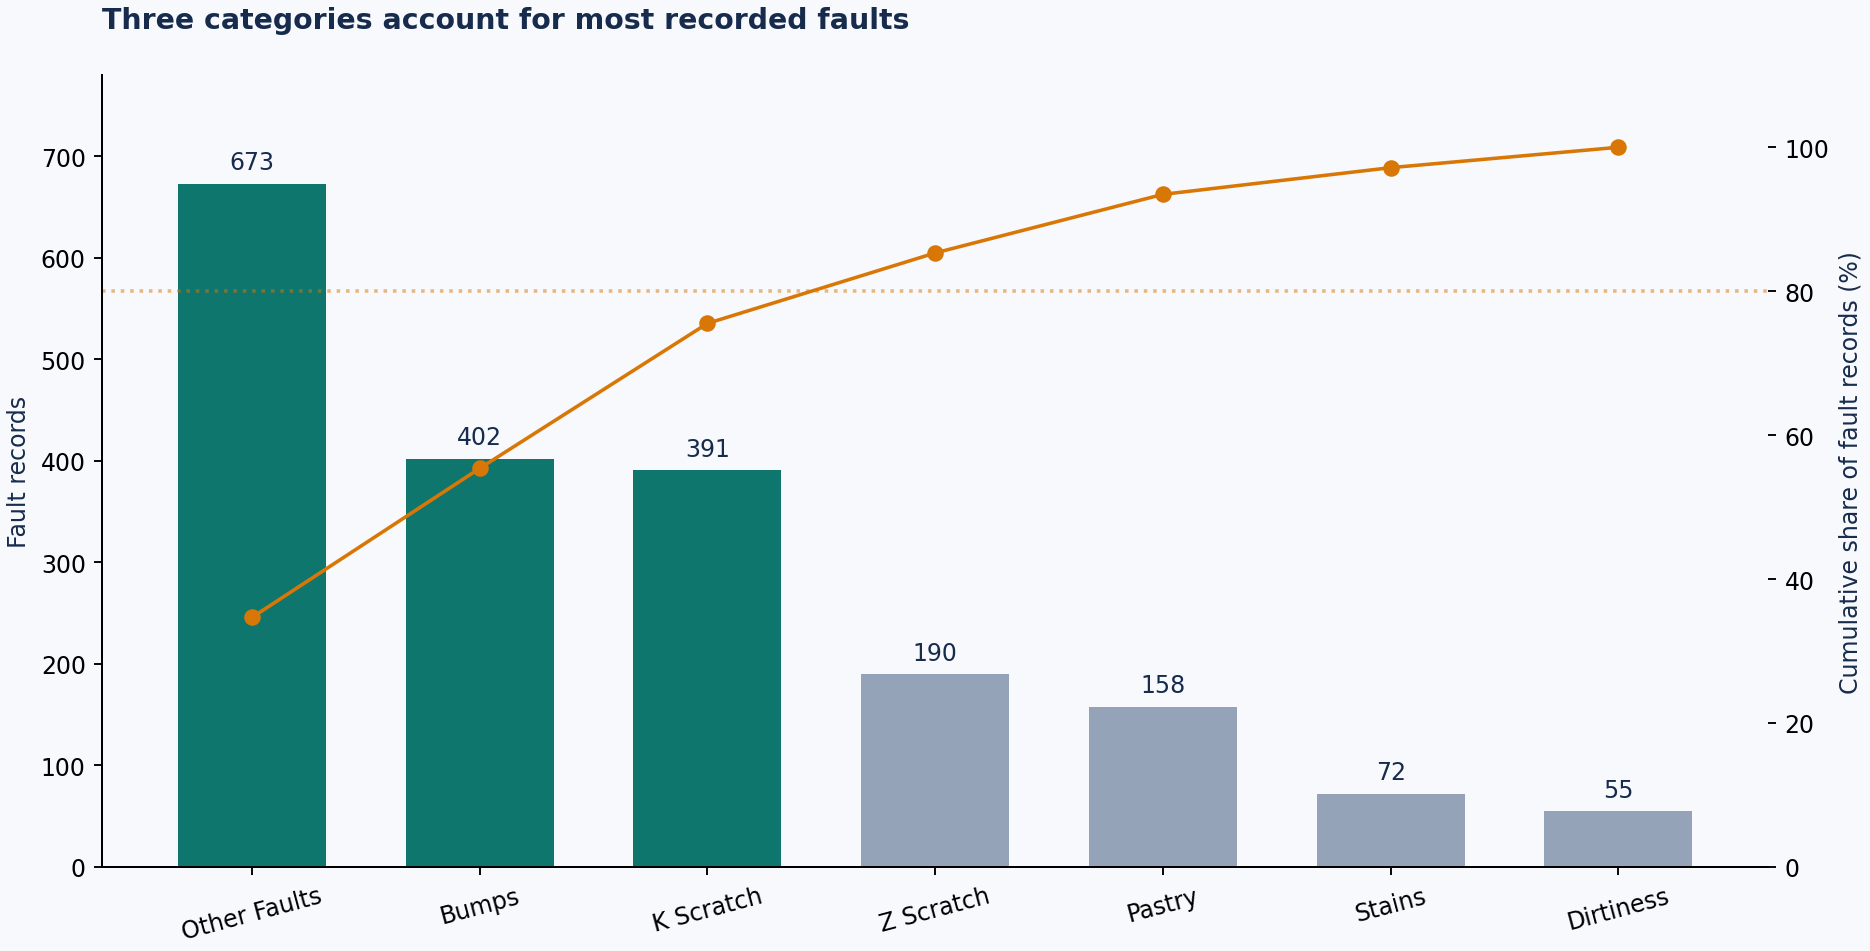

In [5]:
summary = fault_summary(df)
assert summary.records.tolist() == results['fault_pareto'].records.tolist()
print(f'Top-three share: {summary.head(3).record_share_pct.sum():.2f}%')
main()  # Rebuild committed reports and figures from source.
display(Image(filename=str(ROOT/'reports/figures/fault_pareto.png')))

## 4. Compare steel types using the right denominator
A300 and A400 have unequal sample sizes. Compute each fault category as a percentage of that steel type's recorded faults—not a percentage of the combined sample.

,steel_type,fault_type,records,steel_sample_size,within_steel_share_pct
0,A300,Bumps,279,777,35.91
1,A300,Other Faults,266,777,34.23
2,A300,Z Scratch,172,777,22.14
3,A300,Pastry,49,777,6.31
4,A300,Dirtiness,9,777,1.16
5,A300,K Scratch,1,777,0.13
6,A300,Stains,1,777,0.13
7,A400,Other Faults,407,1164,34.97
8,A400,K Scratch,390,1164,33.51
9,A400,Bumps,123,1164,10.57


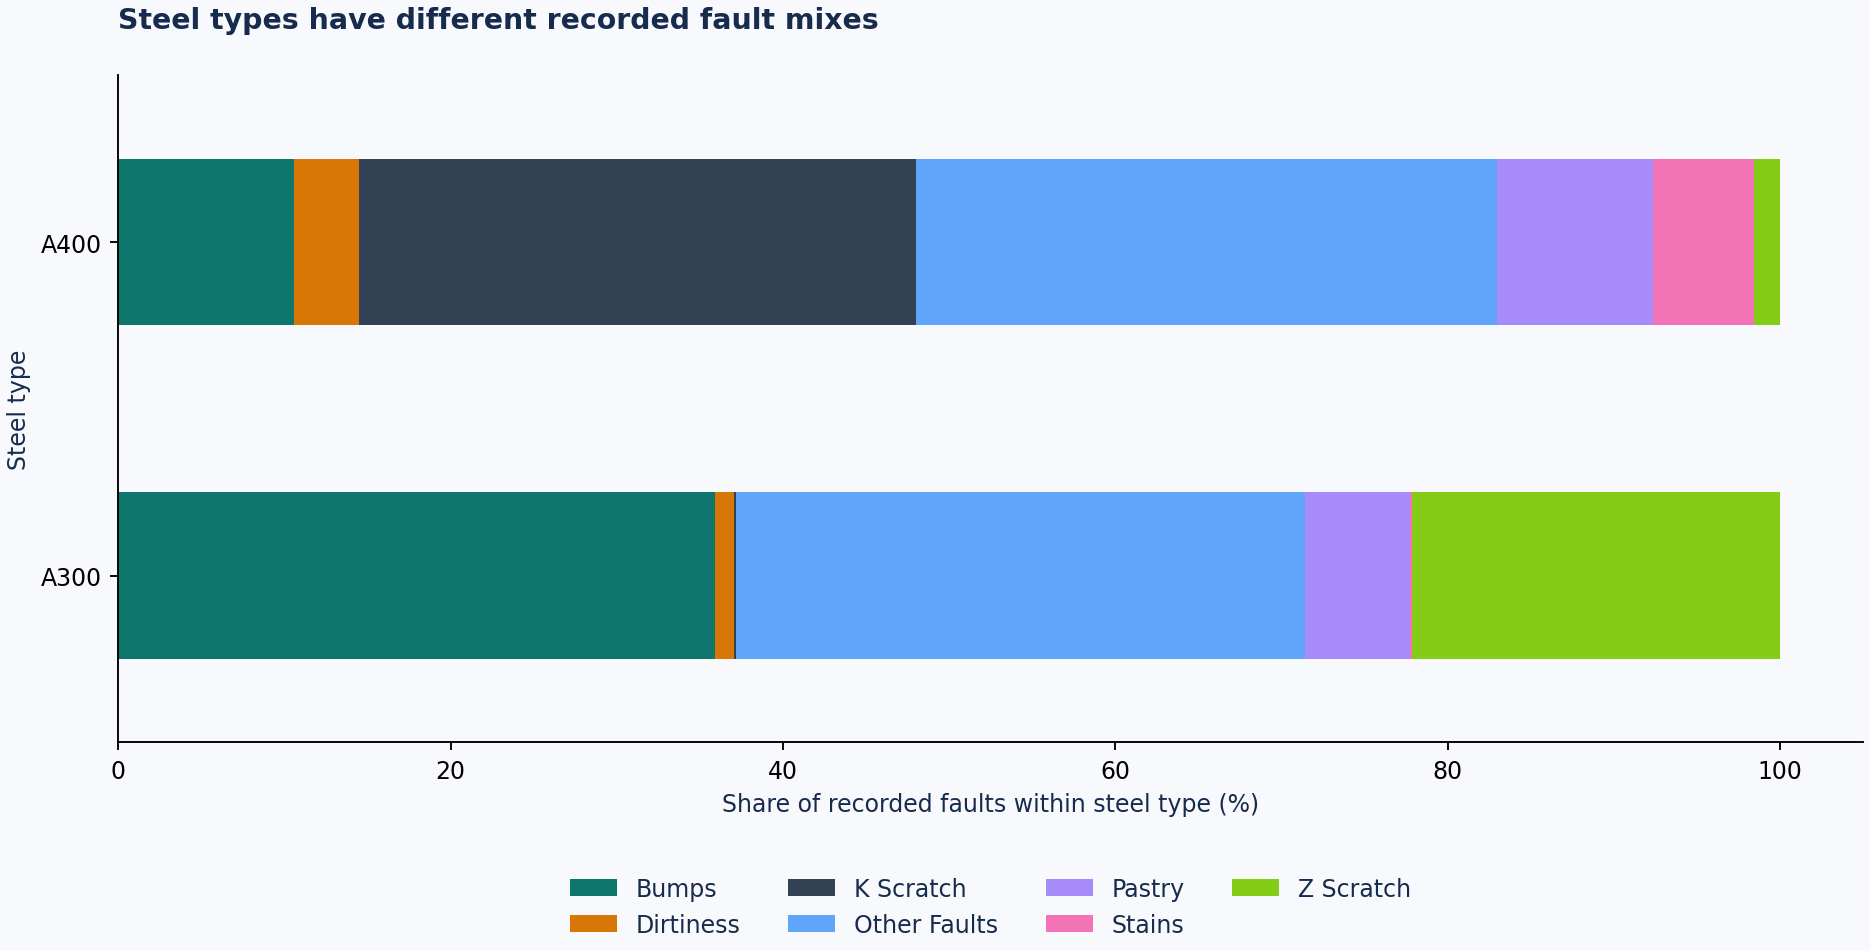

In [6]:
display(results['steel_fault_mix'])
display(Image(filename=str(ROOT/'reports/figures/steel_mix.png')))

**Interpretation:** Bumps comprises 35.91% of A300 fault records versus 10.57% of A400 fault records. This is an association in the sample, not proof that material type causes faults or that one steel has lower production reliability. Only one A300 K Scratch record exists, so its small cell needs particular caution.

## 5. Frequency versus pixel-area concentration
A less frequent category can dominate the summed image measurement. Compare counts, sums and medians. Do not assume that pixel area equals severity, scrap cost, or calibrated physical damage.

,fault_type,records,record_share_pct,total_pixels,median_pixels,pixel_share_pct
3,Other Faults,673,34.67,393282,146.0,10.70
0,Bumps,402,20.71,95863,120.5,2.61
2,K Scratch,391,20.14,2980458,6281.0,81.08
6,Z Scratch,190,9.79,96253,146.0,2.62
4,Pastry,158,8.14,88736,209.0,2.41
5,Stains,72,3.71,1434,16.5,0.04
1,Dirtiness,55,2.83,19992,145.0,0.54


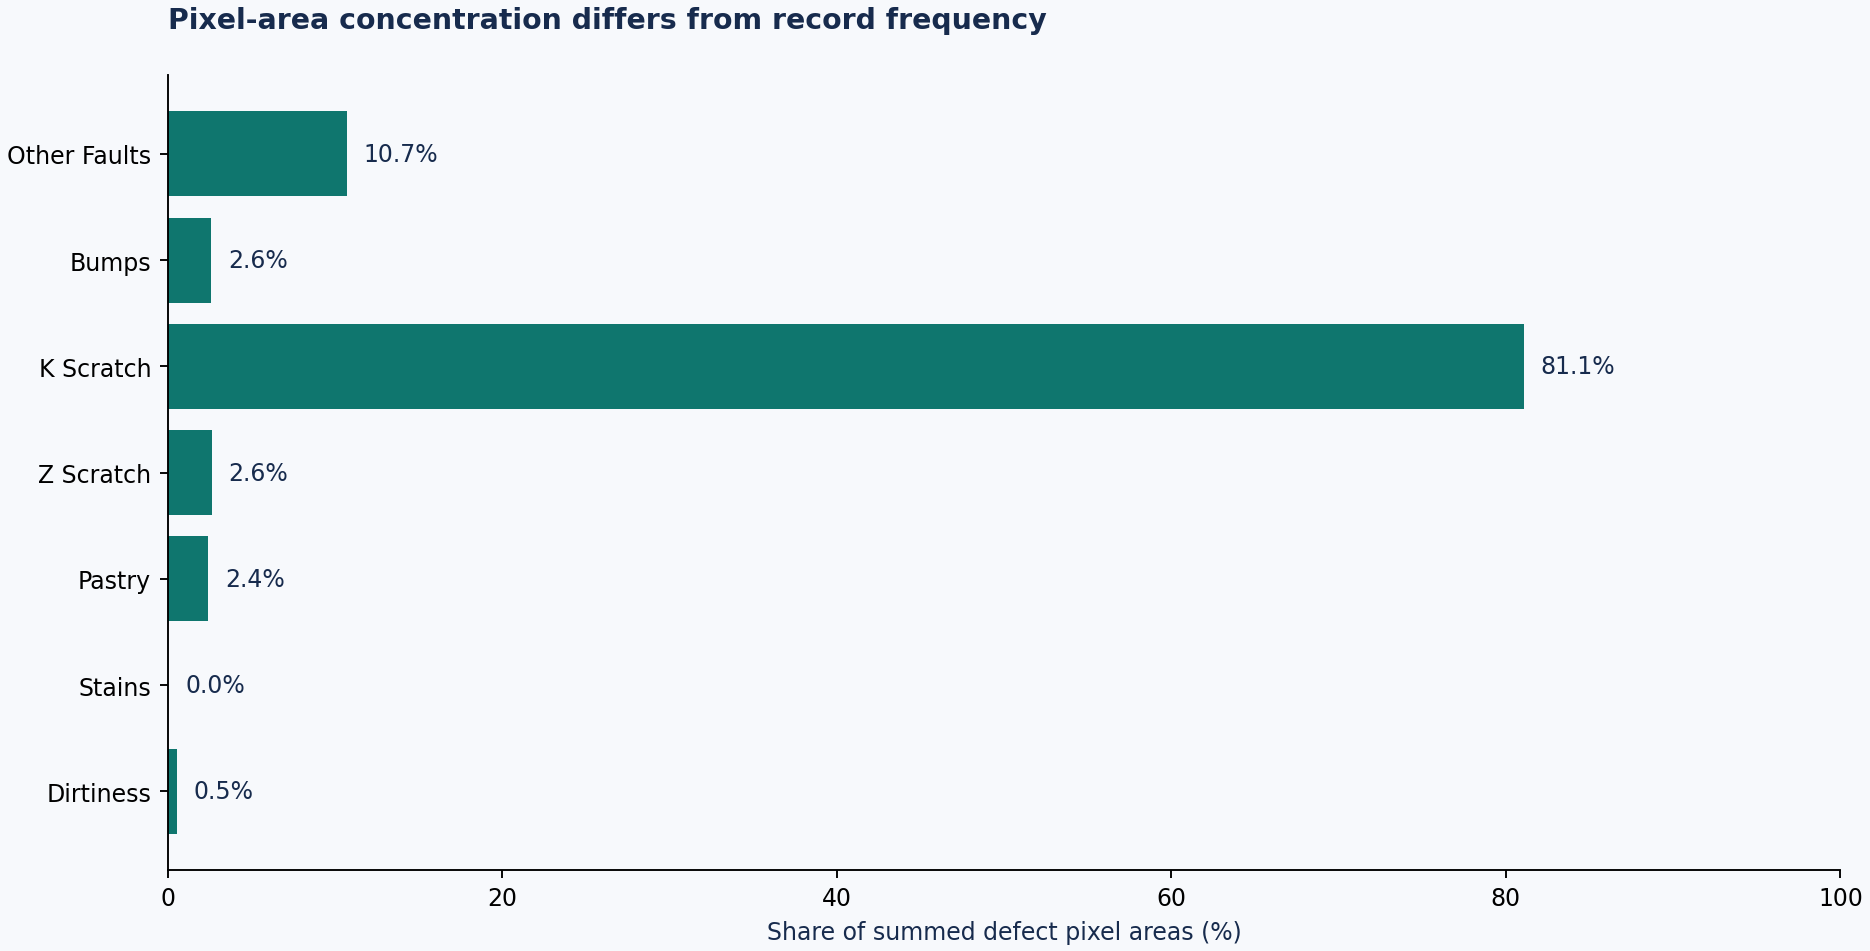

In [7]:
display(summary[['fault_type','records','record_share_pct','total_pixels','median_pixels','pixel_share_pct']].round(2))
display(Image(filename=str(ROOT/'reports/figures/pixel_area_share.png')))

**Interpretation:** K Scratch contributes 20.14% of records and 81.08% of summed defect pixel area. Its median area is 6,281 pixels. This supports further review of this category, contingent on consistent imaging scale and engineering validation.

## 6. Inspect thickness groups
These are exploratory analyst-defined bins, not engineering limits. No physical unit is assumed. Report subgroup sizes alongside category composition.

In [8]:
display(results['thickness_fault_mix'])
display(df.groupby('thickness_band').agg(records=('record_id','size'), median_pixels=('pixels_areas','median')))

,thickness_band,fault_type,records,band_sample_size,within_band_share_pct
0,51-100,Bumps,275,837,32.86
1,51-100,Other Faults,273,837,32.62
2,51-100,Z Scratch,172,837,20.55
3,51-100,Pastry,80,837,9.56
4,51-100,Dirtiness,35,837,4.18
5,51-100,K Scratch,1,837,0.12
6,51-100,Stains,1,837,0.12
7,<=50,K Scratch,390,825,47.27
8,<=50,Other Faults,212,825,25.70
9,<=50,Bumps,92,825,11.15


,records,median_pixels
thickness_band,,
51-100,837,121.0
<=50,825,368.0
>100,279,180.0


## 7. Recommendations and limits

1. Review the broad **Other Faults** category and improve labeling specificity.
2. Inspect representative **K Scratch** cases and validate area/severity measurement.
3. Explore steel/process differences using batch, line, shift and sampling information.
4. Collect production and inspection totals, defect-free controls, timestamps and costs before estimating operational rates or savings.

No implemented intervention or cost reduction is claimed. The dataset was donated in 2010; this is not a current factory audit. See `docs/INTERVIEW_GUIDE.md` for questions to practice.